<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan3/BTOL/ML_T3_BTVN_B3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cac nhan goc: ['tested_positive' 'tested_negative']
Kich thuoc: (768, 8)
Phan bo nhan:
class
0    500
1    268
Name: count, dtype: int64
Gia tri thieu: 652

Accuracy: 0.7012987012987013
Precision: 0.5666666666666667
Recall: 0.6296296296296297
F1-score: 0.5964912280701754

Bao cao phan loai:
                precision    recall  f1-score   support

Khong mac benh       0.79      0.74      0.76       100
      Mac benh       0.57      0.63      0.60        54

      accuracy                           0.70       154
     macro avg       0.68      0.68      0.68       154
  weighted avg       0.71      0.70      0.70       154



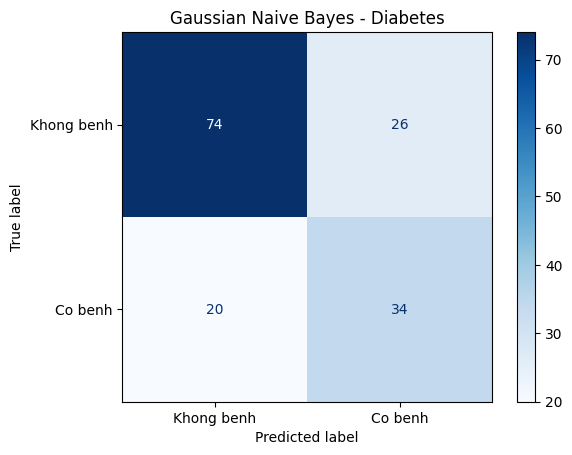


5 MAU DU DOAN:
Thuc te: 0 | Du doan: 1 | Xac suat lop 1: 0.5111
Thuc te: 0 | Du doan: 0 | Xac suat lop 1: 0.3629
Thuc te: 0 | Du doan: 0 | Xac suat lop 1: 0.1872
Thuc te: 1 | Du doan: 0 | Xac suat lop 1: 0.1006
Thuc te: 0 | Du doan: 0 | Xac suat lop 1: 0.0136


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    ConfusionMatrixDisplay
)

# 1. Tai Pima Indians Diabetes
data = fetch_openml(data_id=37, as_frame=True)

X = data.data.apply(pd.to_numeric, errors="coerce")
y_raw = data.target.astype(str).str.lower().str.strip()

print("Cac nhan goc:", y_raw.unique())

# 2. Chuyen nhan thanh 0 va 1
mapping = {
    "tested_negative": 0,
    "tested_positive": 1,
    "negative": 0,
    "positive": 1,
    "0": 0,
    "1": 1
}

y = y_raw.map(mapping)
valid = y.notna()

X = X.loc[valid]
y = y.loc[valid].astype(int)

# Mot so chi so bang 0 co the bieu thi gia tri thieu
missing_columns = [
    "plas", "pres", "skin", "insu", "mass"
]
for col in missing_columns:
    if col in X.columns:
        X.loc[X[col] == 0, col] = np.nan

print("Kich thuoc:", X.shape)
print("Phan bo nhan:")
print(y.value_counts())
print("Gia tri thieu:", X.isna().sum().sum())

# 3. Chia train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Bu gia tri thieu + GaussianNB
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("nb", GaussianNB())
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

# 5. Danh gia
print("\nAccuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, zero_division=0))
print("Recall:", recall_score(y_test, pred, zero_division=0))
print("F1-score:", f1_score(y_test, pred, zero_division=0))

print("\nBao cao phan loai:")
print(classification_report(
    y_test, pred,
    target_names=["Khong mac benh", "Mac benh"],
    zero_division=0
))

# 6. Ma tran nham lan
ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["Khong benh", "Co benh"],
    cmap="Blues"
)
plt.title("Gaussian Naive Bayes - Diabetes")
plt.show()

# 7. Du doan 5 mau trong tap kiem tra
prob = model.predict_proba(X_test)[:, 1]

print("\n5 MAU DU DOAN:")
for i in range(5):
    print(
        "Thuc te:", y_test.iloc[i],
        "| Du doan:", pred[i],
        "| Xac suat lop 1:", round(prob[i], 4)
    )
